# Customer Churn Analysis – Telecommunications

**Methodology:** CRISP-DM (Cross-Industry Standard Process for Data Mining)

CRISP-DM splits a data project into 6 phases:

1. **Business Understanding** – What problem are we solving?
2. **Data Understanding** – What does our data look like?
3. **Data Preparation** – Cleaning the data so it can be used.
4. **Modeling** – Building a simple predictive model.
5. **Evaluation** – Checking whether the model is good enough.
6. **Deployment** – How the company can use the results.

### Dataset source

- **Name:** IBM Telco Customer Churn
- **Publisher:** IBM. It is a sample dataset IBM created to demonstrate its analytics tools (IBM Cognos Analytics / Watson). It describes a **fictional** telecom company in California, so it is not real private customer data.
- **Download link used in this project:** https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv
- The same file is also on Kaggle as *"Telco Customer Churn"* (blastchar), named `WA_Fn-UseC_-Telco-Customer-Churn.csv`.
- **Size:** 7,043 customers (rows) and 21 columns. Each row is one customer.

---
# 1. Business Understanding

### The business problem
A telecom company loses money every time a customer cancels their subscription. This is called **churn**.
Winning a new customer usually costs much more than keeping an existing one (advertising, discounts, installation, etc.).
So the company wants to know **which customers are likely to leave, and why**.

### Project objectives
1. **Understand the data** that describes the customers (services, contract, payments).
2. **Clean and prepare** the data so it is correct and usable.
3. **Find the main factors** linked to churn (for example contract type or monthly price).
4. **Build a simple model** (Logistic Regression) that predicts whether a customer will churn.
5. **Give recommendations** the company can use to reduce churn.

### Questions we want to answer
- What percentage of customers leave?
- Do customers with short contracts leave more often?
- Do new customers leave more than long-time customers?
- Do customers who pay more per month leave more often?

---
# 2. Data Understanding

In this phase we **look** at the data without changing it. We want to know its size, its columns, their types, and whether there are problems such as missing values or duplicates.

### 2.1 Import the libraries
- **pandas**: works with tables of data (called *DataFrames*).
- **matplotlib** and **seaborn**: draw charts.

In [1]:
import pandas as pd               # data tables
import matplotlib.pyplot as plt   # basic charts
import seaborn as sns             # nicer statistical charts (built on matplotlib)

### 2.2 Load the dataset
`pd.read_csv()` reads the CSV file and stores it in a DataFrame called `df`.
The file must be in a folder named `data` next to this notebook.

In [2]:
# Read the CSV file into a DataFrame
df = pd.read_csv("data/Telco-Customer-Churn.csv")

### 2.3 Display the first rows
`head()` shows the first 5 rows. This gives a quick idea of what each column contains.

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 2.4 Number of rows and columns
`shape` returns a pair: (number of rows, number of columns).

In [4]:
rows, columns = df.shape
print("Number of rows (customers):", rows)
print("Number of columns:", columns)

Number of rows (customers): 7043
Number of columns: 21


**What the columns mean:**

| Group | Columns |
|---|---|
| Identifier | `customerID` |
| Customer profile | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Services | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Account | `tenure` (months as a customer), `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges` |
| **Target** (what we want to predict) | `Churn` (Yes = the customer left) |

### 2.5 Data types
`info()` shows each column's data type and how many non-empty values it has.
- `int64` = whole numbers, `float64` = decimal numbers, `str` = text.
- (In pandas versions older than 3.0, text columns are shown as `object` instead of `str`.)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Observation:** `TotalCharges` should be a number (an amount of money), but its type is `str` (text).
This tells us some values in this column are not valid numbers. We look into this in step 2.8.

### 2.6 Basic statistics
`describe()` calculates statistics for the numeric columns: count, mean, standard deviation, min, max and quartiles.

In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


**Observations:**
- `tenure` goes from 0 to 72 months. A tenure of 0 means a brand-new customer.
- `MonthlyCharges` goes from about 18 to 119. These values look realistic, so there are no strange outliers.
- `TotalCharges` is **not** in this table because pandas sees it as text.
- `SeniorCitizen` is stored as 0/1, while the other yes/no columns use "Yes"/"No". We handle this inconsistency in Data Preparation.

### 2.7 Values in the text (categorical) columns
For each text column, we print the list of **different values** it contains (`unique()`).
This lets us spot spelling mistakes or inconsistent categories.
We skip `customerID` (every value is different) and `TotalCharges` (it should be numeric).

In [11]:
for column in df.select_dtypes(include="str").columns:   # loop over the text columns only
    if column not in ["customerID", "TotalCharges"]:
        print(column, ":", df[column].unique())

gender : <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner : <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents : <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService : <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines : <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService : <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity : <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup : <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection : <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport : <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV : <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingMovies : <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Contract : <StringArray>
['Month-to-month', 

**Observations:**
- There are no spelling mistakes or upper/lower-case variants (e.g. no "yes" vs "Yes"), so the categories are clean.
- Some columns have a third value: **"No internet service"** or **"No phone service"**. For example, a customer without internet obviously has no `OnlineSecurity`. These values mean the same thing as "No", so we simplify them in Data Preparation.

### 2.8 Missing values
`isnull().sum()` counts the empty cells (NaN) in each column.

In [12]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Pandas reports **0 missing values**. But we already saw that `TotalCharges` is text, which is suspicious.
Pandas only recognises truly *empty* cells as missing. A cell containing a **space `" "`** looks empty to a human, but pandas reads it as text.
Let's count the cells that contain only a space:

In [13]:
# Compare every cell with " " and count the matches in each column
(df == " ").sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

There are **11 hidden missing values** in `TotalCharges`. Let's look at these customers:

In [43]:
df[df["TotalCharges"] == " "][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Observation:** all 11 customers have `tenure = 0`. They just joined and have not received their first bill yet, so their total amount paid is empty.
This explains why the value is missing. We fix it in Data Preparation.

### 2.9 Duplicates
- `duplicated().sum()` counts rows that are exact copies of an earlier row.
- We also check that each `customerID` appears only once.

In [14]:
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated customer IDs:", df["customerID"].duplicated().sum())

Duplicated rows: 0
Duplicated customer IDs: 0


**Observation:** there are **no duplicates**. Every row is a different customer.

### 2.10 Target variable: how many customers churn?
`value_counts()` counts each value. With `normalize=True` it gives proportions instead of counts.

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


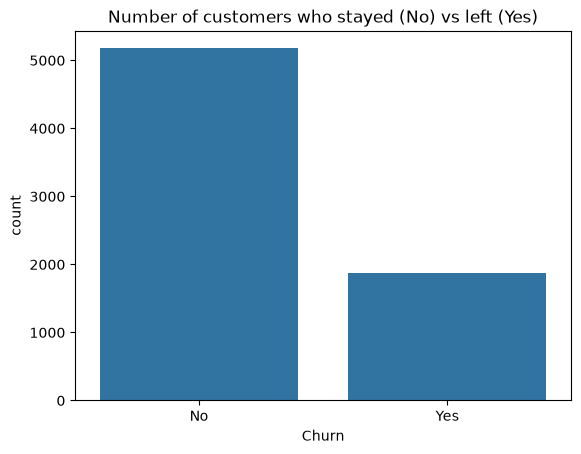

In [15]:
print(df["Churn"].value_counts())
print()
print((df["Churn"].value_counts(normalize=True) * 100).round(1))   # percentages

sns.countplot(data=df, x="Churn")
plt.title("Number of customers who stayed (No) vs left (Yes)")
plt.show()

**Observation:** about **26.5 %** of customers left the company. The classes are **unbalanced**: there are many more "No" than "Yes".
Remember this for the Evaluation phase.

### 2.11 Churn by contract type
`pd.crosstab()` builds a table that crosses two columns. With `normalize="index"` each row adds up to 100 %, so we see the churn **rate** for each contract type.

Churn             No   Yes
Contract                  
Month-to-month  57.3  42.7
One year        88.7  11.3
Two year        97.2   2.8


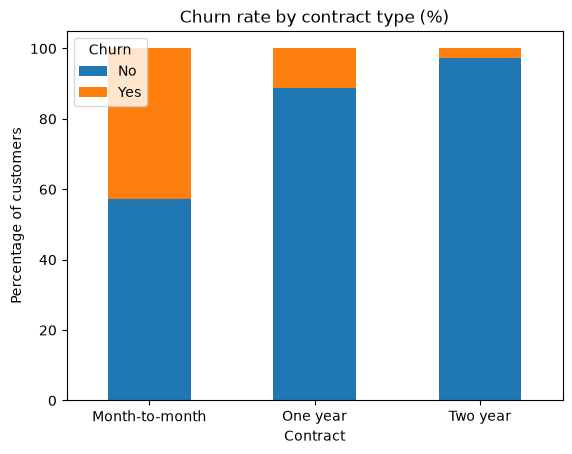

In [46]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
print(contract_churn.round(1))

contract_churn.plot(kind="bar", stacked=True)
plt.title("Churn rate by contract type (%)")
plt.ylabel("Percentage of customers")
plt.xticks(rotation=0)
plt.show()

**Observation:** **42.7 %** of month-to-month customers leave, compared with only **11.3 %** on one-year contracts and **2.8 %** on two-year contracts. Contract type looks like a strong factor.

### 2.12 Churn by tenure (how long the customer has stayed)
A histogram shows how many customers fall in each range of tenure. `hue="Churn"` gives each group its own colour.

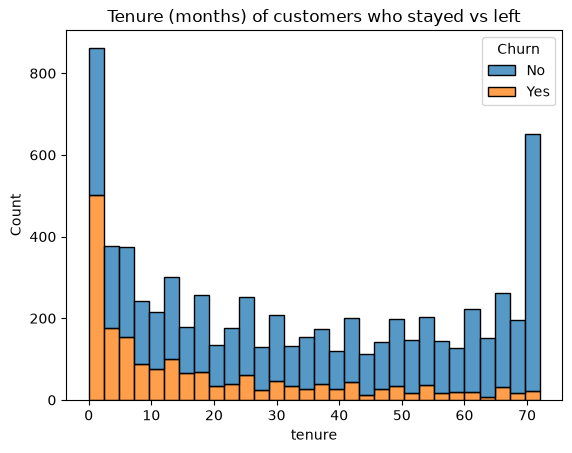

In [16]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack")
plt.title("Tenure (months) of customers who stayed vs left")
plt.show()

**Observation:** most customers who leave do so in the **first months**. Long-time customers rarely churn.

### 2.13 Churn by monthly charges
A boxplot shows the median (middle line) and the spread of values for each group.

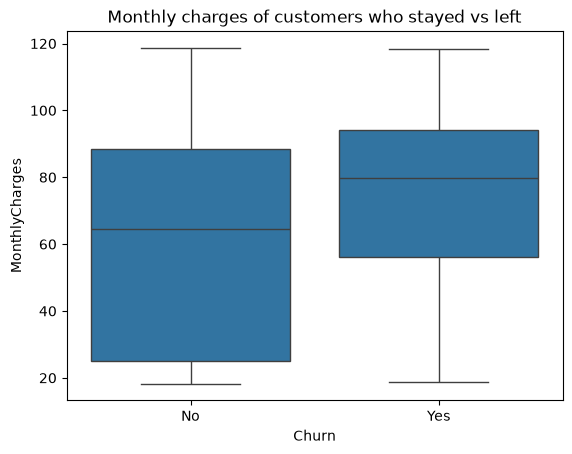

In [17]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly charges of customers who stayed vs left")
plt.show()

**Observation:** customers who leave tend to pay **higher monthly charges**.

### Summary of Data Understanding

| Check | Result | Action needed? |
|---|---|---|
| Size | 7,043 rows, 21 columns | – |
| Missing values (NaN) | 0 visible, but **11 blank `" "`** values in `TotalCharges` | **Yes** |
| Data types | `TotalCharges` stored as text instead of number | **Yes** |
| Duplicates | 0 duplicated rows, 0 duplicated IDs | No |
| Inconsistent values | `SeniorCitizen` uses 0/1; "No internet/phone service" mean "No" | **Yes** |
| Spelling / case errors | None found | No |
| Outliers | Ranges are realistic | No |

---
# 3. Data Preparation

In this phase we **fix the problems** found above. Each step explains *what* we do and *why*.

We work on a **copy** of the data so the original `df` stays unchanged and we can always compare with it.

In [19]:
df_clean = df.copy()   # copy, so changes don't affect the original df

### 3.1 Correct the data type of `TotalCharges`
`pd.to_numeric()` converts text to numbers.
With `errors="coerce"`, any value that can't be converted (here the `" "` spaces) becomes **NaN**, a real missing value that pandas can recognise.

In [20]:
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")

print("New type:", df_clean["TotalCharges"].dtype)
print("Missing values in TotalCharges:", df_clean["TotalCharges"].isnull().sum())

New type: float64
Missing values in TotalCharges: 11


The column is now `float64` (a number), and the 11 blanks are now proper missing values (NaN).

### 3.2 Handle the missing values
We have two simple options:
- **Delete** the 11 rows (only 0.16 % of the data).
- **Fill** them with a sensible value.

We choose to **fill them with 0**. These customers have `tenure = 0`, meaning they joined less than a month ago and haven't paid anything yet. A total of 0 is therefore the logically correct value, not a guess.
`fillna(0)` replaces NaN with 0.

In [22]:
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

print("Missing values in TotalCharges:", df_clean["TotalCharges"].isnull().sum())

Missing values in TotalCharges: 0


### 3.3 Duplicates
In step 2.9 we found **0 duplicated rows** and **0 duplicated customer IDs**, so **nothing needs to be removed**.

A possible question: *"What if we ignore the customerID column?"* Let's check:

In [23]:
print("Identical rows if we ignore customerID:", df_clean.drop(columns="customerID").duplicated().sum())

Identical rows if we ignore customerID: 22


We find 22 identical rows. They belong to **different customers** (different IDs) who happen to have the same profile, for example new customers with the same basic subscription. That's normal in real data, so these are **not errors** and we **keep** them.

### 3.4 Handle inconsistent values

**a) `SeniorCitizen` uses 0/1 while all other yes/no columns use "Yes"/"No".**
We convert it to "Yes"/"No" so all similar columns follow the same format.
`map()` replaces each value using a dictionary: 0 → "No", 1 → "Yes".

In [24]:
df_clean["SeniorCitizen"] = df_clean["SeniorCitizen"].map({0: "No", 1: "Yes"})

print(df_clean["SeniorCitizen"].value_counts())

SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64


**b) "No internet service" and "No phone service"**
In the internet-related columns, "No internet service" simply means the customer doesn't have that option, so it's equivalent to "No".
We replace it with "No". **No information is lost**, because the `InternetService` column still says whether the customer has internet. The same applies to "No phone service" in `MultipleLines` (the `PhoneService` column keeps that information).

`replace(old, new)` changes every occurrence of one value into another.

In [25]:
internet_columns = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                    "TechSupport", "StreamingTV", "StreamingMovies"]

for column in internet_columns:
    df_clean[column] = df_clean[column].replace("No internet service", "No")

df_clean["MultipleLines"] = df_clean["MultipleLines"].replace("No phone service", "No")

# Check: each of these columns should now only contain "Yes" and "No"
for column in internet_columns + ["MultipleLines"]:
    print(column, ":", df_clean[column].unique())

OnlineSecurity : <StringArray>
['No', 'Yes']
Length: 2, dtype: str
OnlineBackup : <StringArray>
['Yes', 'No']
Length: 2, dtype: str
DeviceProtection : <StringArray>
['No', 'Yes']
Length: 2, dtype: str
TechSupport : <StringArray>
['No', 'Yes']
Length: 2, dtype: str
StreamingTV : <StringArray>
['No', 'Yes']
Length: 2, dtype: str
StreamingMovies : <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines : <StringArray>
['No', 'Yes']
Length: 2, dtype: str


### 3.5 Remove the `customerID` column
`customerID` is just a label (like a name). It gives no information about the customer's behaviour, so it can't help explain churn.
We remove it with `drop()`.

In [26]:
df_clean = df_clean.drop(columns="customerID")

### 3.6 Final check of the cleaned data
We confirm there are no missing values and that the types are correct.

In [27]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   str    
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [28]:
df_clean.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Summary of Data Preparation

| # | Problem | Operation | Reason |
|---|---|---|---|
| 1 | `TotalCharges` stored as text | Converted to number (`pd.to_numeric`) | It is an amount of money |
| 2 | 11 blank values in `TotalCharges` | Filled with 0 (`fillna`) | These customers have tenure 0, so they haven't paid anything yet |
| 3 | Duplicates | **None found**, nothing removed | – |
| 4 | `SeniorCitizen` in 0/1 format | Converted to "Yes"/"No" (`map`) | Same format as the other yes/no columns |
| 5 | "No internet service" / "No phone service" | Replaced with "No" (`replace`) | Same meaning; information kept in other columns |
| 6 | `customerID` | Removed (`drop`) | An identifier has no predictive value |

The dataset now has **7,043 rows, 20 columns, no missing values** and consistent categories.

---
# 4. Modeling

We now build a **Logistic Regression** model. It is one of the simplest classification models: it estimates the **probability** that a customer churns (between 0 and 1). If the probability is above 0.5, it predicts "churn".

A model only understands **numbers**, so first we convert the text columns.

### 4.1 Prepare the data for the model

1. **Target `y`:** the `Churn` column, converted to numbers: "Yes" → 1, "No" → 0.
2. **Features `X`:** all the other columns.
3. **One-hot encoding** with `pd.get_dummies()`: each text column becomes one or more 0/1 columns.
   For example `Contract` becomes `Contract_One year` and `Contract_Two year`. A customer with 0 in both is month-to-month.
   `drop_first=True` removes one category per column because it can be deduced from the others (this avoids redundant columns).

In [29]:
# Target: 1 = churn, 0 = stays
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

# Features: every column except Churn, with text columns turned into 0/1 columns
X = pd.get_dummies(df_clean.drop(columns="Churn"), drop_first=True, dtype=int)

print("Shape of X:", X.shape)
X.head()

Shape of X: (7043, 23)


,tenure,MonthlyCharges,TotalCharges,gender_Male,SeniorCitizen_Yes,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,...,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1,29.85,29.85,0,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
1,34,56.95,1889.50,1,0,0,0,1,0,0,...,1,0,0,0,1,0,0,0,0,1
2,2,53.85,108.15,1,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,45,42.30,1840.75,1,0,0,0,0,0,0,...,1,1,0,0,1,0,0,0,0,0
4,2,70.70,151.65,0,0,0,0,1,0,1,...,0,0,0,0,0,0,1,0,1,0


### 4.2 Split into training and test sets
We split the data:
- **80 % training set**: the model learns from it.
- **20 % test set**: hidden from the model during training, then used to check how well it works on **new** customers.

`stratify=y` keeps the same churn percentage (about 26.5 %) in both sets.
`random_state=42` makes the random split the same every time we run the notebook.

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (5634, 23)
Test set: (1409, 23)


### 4.3 Scale the features
The columns have very different ranges: `TotalCharges` goes up to about 8,700 while the 0/1 columns only go up to 1.
Logistic Regression works better when all columns are on a similar scale.
`StandardScaler` transforms each column so it has a mean of 0 and a standard deviation of 1.

**Important:** we `fit` the scaler on the **training set only**, then apply it to the test set. The test set must stay "unseen", otherwise we would be cheating a little (this is called *data leakage*).

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn mean/std from training data, then scale it
X_test_scaled = scaler.transform(X_test)         # apply the same scaling to test data

### 4.4 Train the Logistic Regression model
`fit()` is where the model learns the relationship between the features and churn.
`max_iter=1000` gives the algorithm enough steps to finish learning.

In [33]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

# Predict churn (0 or 1) for the customers in the test set
y_pred = model.predict(X_test_scaled)

---
# 5. Evaluation

We compare the model's predictions (`y_pred`) with the real answers (`y_test`).

### 5.1 Accuracy
**Accuracy** = the percentage of correct predictions.

But the classes are unbalanced: a "lazy" model that always predicts "No churn" would already be right about 73.5 % of the time. We use this as a **baseline** to compare against.

In [35]:
from sklearn.metrics import accuracy_score

baseline = (y_test == 0).mean()   # accuracy if we always predict "No churn"
accuracy = accuracy_score(y_test, y_pred)

print("Baseline accuracy (always 'No'):", round(baseline * 100, 1), "%")
print("Model accuracy:", round(accuracy * 100, 1), "%")

Baseline accuracy (always 'No'): 73.5 %
Model accuracy: 80.7 %


### 5.2 Confusion matrix
The confusion matrix shows **what kind** of mistakes the model makes:

| | Predicted: Stay | Predicted: Churn |
|---|---|---|
| **Actually stayed** | True Negative ✔ | False Positive ✘ (false alarm) |
| **Actually churned** | False Negative ✘ (missed churner) | True Positive ✔ |

For the company, **False Negatives are the most costly**: these are customers who leave without being detected.

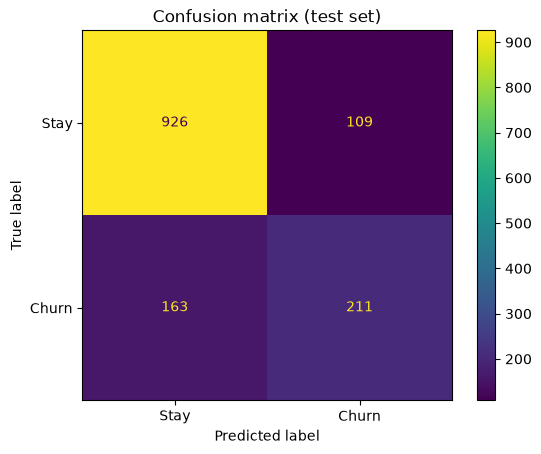

In [36]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Stay", "Churn"])
plt.title("Confusion matrix (test set)")
plt.show()

### 5.3 Precision and Recall
For the **Churn** class (1):
- **Precision**: of the customers the model *flagged* as churners, how many really left?
- **Recall**: of the customers who *really* left, how many did the model find?
- **F1-score**: a single number that balances precision and recall.

In [37]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=["Stay", "Churn"]))

              precision    recall  f1-score   support

        Stay       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



**How to read the results:**
- **Accuracy is 80.7 %**, compared with 73.5 % for the baseline. The model really learned something, but the gain is about 7 points, not 80.
- **Precision for Churn = 0.66**: when the model says "this customer will leave", it is right 2 times out of 3.
- **Recall for Churn = 0.56**: the model finds 56 % of the customers who really leave, so it misses about 44 % of them.
- The model is much better at recognising customers who **stay** (recall 0.89) than those who **leave**. This is normal for a simple model on unbalanced data (there are far fewer churners to learn from).

### 5.4 Which factors influence churn?
Each feature gets a **coefficient** in Logistic Regression:
- **Positive** coefficient → increases the probability of churn.
- **Negative** coefficient → decreases the probability of churn (the customer is more loyal).

Because we scaled the data, we can compare the sizes of the coefficients to see which features matter most.

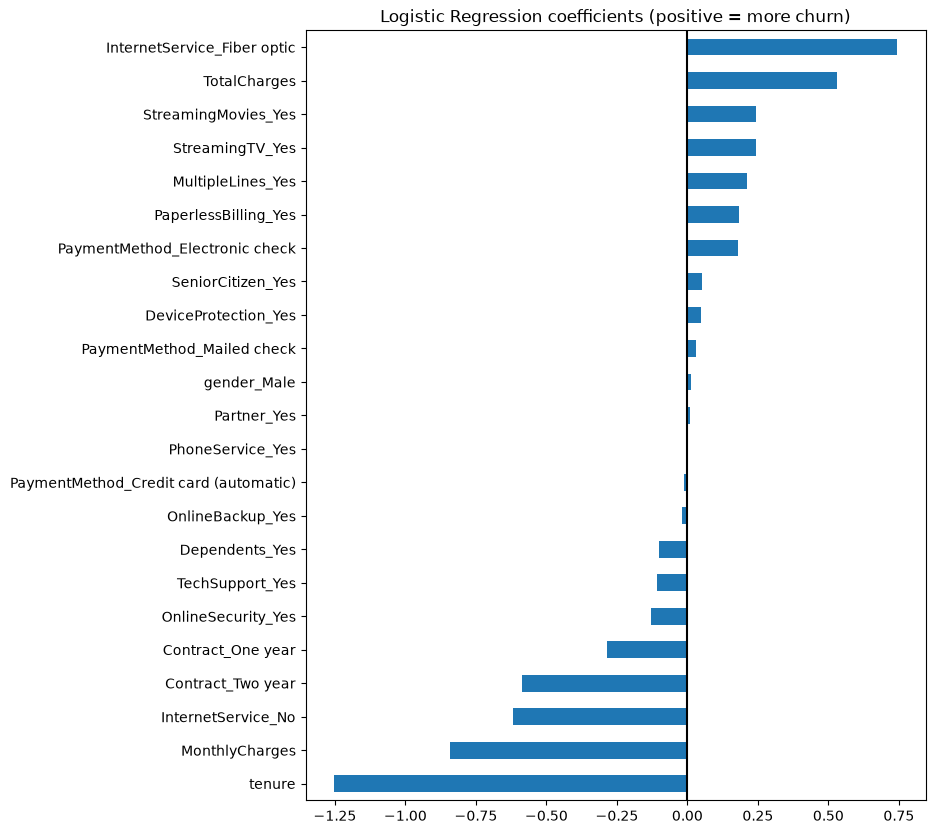

In [38]:
coefficients = pd.Series(model.coef_[0], index=X.columns).sort_values()

coefficients.plot(kind="barh", figsize=(8, 10))
plt.title("Logistic Regression coefficients (positive = more churn)")
plt.axvline(0, color="black")
plt.show()

**Interpretation:**
- **`tenure`** has the strongest negative coefficient (−1.25): the longer someone has been a customer, the less likely they are to leave.
- **Two-year (−0.59) and one-year (−0.29) contracts** reduce churn compared with month-to-month.
- **Fiber optic** internet has the strongest positive coefficient (+0.75): these customers leave more often.
- **Electronic check** payment (+0.18) and **paperless billing** (+0.18) also slightly increase churn.
- `gender` and `Partner` have coefficients close to 0, so they have almost no effect.
- This matches what we saw in Data Understanding (sections 2.11 – 2.12).

**Why is `MonthlyCharges` negative, when the chart in 2.13 showed churners pay more?**
Some columns are strongly related to each other:
- The monthly price is mostly determined by the **services** (fiber optic, streaming TV, etc.), which are already separate columns in the model.
- `TotalCharges` ≈ `tenure` × `MonthlyCharges`.

When columns contain overlapping information, the model splits the effect between them in ways that are hard to read on their own (this is called **multicollinearity**). Here, the "expensive customers leave" effect is mostly captured by `InternetService_Fiber optic` and the streaming columns.
**Lesson:** for related columns, rely on the simple charts from Data Understanding rather than on a single coefficient.